# DEEP Practical 1: Machine learning refresher and an introduction to PyTorch

We will begin with a revision of the concepts of machine learning, loss functions and optimisation. We will use a trivial example to get started. We'll also see something new: the concept of differentiable programming using PyTorch. This makes a lot of what we want to do in machine learning extremely easy to implement.

*Machine learning* is a computational approach in which a system learns to map inputs to outputs by "learning" from training data. In reality, "learning" means *optimisation* (usually minimisation) of a *loss function*. In the case of *supervised learning* our training data provides pairs of inputs and the corresponding desired output. Our "machine" is a function of a particular form whose behaviour is determined by some parameters. Our job is to find the parameters that give a function that maps input to output such that the loss over the training set is minimised.

## A trivial example: the constant machine

Imagine a machine learning task where you need to predict a scalar value - i.e. the machine has a single output. Maybe we want to predict the height of people taking DEEP. *But*, this machine has *zero inputs*. In that case, the machine must always predict the same single value. It's a very trivial machine that just always returns a constant since it has no input from which to change its behaviour. What would be the best value for the machine to always predict?

Simply the mean average! Or perhaps some other kind of average (depending on how you define "centrality" for your application).

You were taught the formula for computing the mean back in secondary school:

$$\bar{x} = \frac{1}{n} \sum_{i=1}^n x_i$$

You should all find it easy to compute this in python/numpy. Let's start by generating a dataset of 9 random numbers:

In [28]:
import numpy as np

n = 9
x = np.random.rand(n)

and then compute the mean average:

In [29]:
mean = 1.0/float(n) * np.sum(x)
print(mean)

0.6226357745336514


Of course, numpy has mean average as a built in function:

In [30]:
mean = np.mean(x)
print(mean)

0.6226357745336515


## Deriving the mean

So far so simple...

But do you know *why* that's the formula for the mean?

###Mean as optimisation problem

Actually, this formula is the solution to an optimisation problem. It is the value that minimises the squared differences to all data points:

$$\bar{x}=\arg\min_{\bar{x}} \sum_{i=1}^n (\bar{x}-x_i)^2$$

In other words, if we defined sum of squared differences as our loss function and solved the resulting optimisation problem, we would get the mean as the answer.

So, how is the formula we know for the mean derived from this optimisation problem? The answer is that this optimisation problem has a *closed form solution*. This means that we can write down an equation that solves it exactly, i.e. provides the *global optimum*. To do so, we only need A-level standard maths.

###Thought you'd never have to do differentiation again?

How do we minimise a function? We need to find the *stationary points* which we get by differentiating the function, setting to zero and solving. It's a bit of a painful process for the function above, but let's do it. Start by expanding the summation and square, then multiply out the brackets and collect like terms:

$$\begin{aligned}\sum_{i=1}^n (\bar{x}-x_i)^2 &= (\bar{x}-x_1)(\bar{x}-x_1) + \dots + (\bar{x}-x_n)(\bar{x}-x_n) \\
&= \bar{x}^2 - 2x_1\bar{x} + x_1^2 + \dots \bar{x}^2 - 2x_n\bar{x} + x_n^2 \\
&= n\bar{x}^2 - 2\bar{x}\sum_{i=1}^nx_i + \sum_{i=1}^nx_i^2\end{aligned}$$

In terms of $\bar{x}$, can you see what sort of function we have now? It's just a quadratic! i.e.

$$f(\bar{x}) = a\bar{x}^2 + b\bar{x} + c$$

where $a$, $b$ and $c$ happen to be:

$$a=n,\quad b=-2\sum_{i=1}^nx_i,\quad c=\sum_{i=1}^nx_i^2.$$

Now, hopefully you all remember how to differentiate $a\bar{x}^2 + b\bar{x} + c$? It's simply:

$$\frac{\partial f}{\partial \bar{x}} = 2a\bar{x} + b$$

Now set to zero and solve:

$$\begin{aligned}2a\bar{x} + b&=0\\
\bar{x}=\frac{-b}{2a}\end{aligned}$$

Now plug in $a$ and $b$:

$$\bar{x}=\frac{2\sum_{i=1}^nx_i}{2n}=\frac{1}{n} \sum_{i=1}^n x_i$$

It's the formula for the mean that we know and love!

**Wow - that was pretty painful right?!**

And that was for just about the most trivial machine learning problem you could possibly imagine (no inputs, one output, sum of squared errors as the loss). Squared errors (i.e. a quadratic function) have always been popular because the function to find the minimum is linear and solving linear equations is easy. But now consider a multilayer perceptron with many layers, nonlinear activation functions and a logistic regression layer on the end for classification (or some other complicated loss function). Imagine trying to differentiate that by hand! (And it wouldn't have a closed form solution anyway...)

##Differentiable programming

We'll now see a totally different way of solving optimisation problems (and it might mean you never have to do differentiation by hand again!) The idea is that we simply write code that computes the loss function, i.e. the thing we want to minimise, from some given input.

A differentiable programming language can then automatically differentiate backwards from our loss function, all the way through our series of instructions right back to the input(s). At any point through this chain of differentiation, we can ask: what is the gradient of the loss function with respect to some parameters at this point in the chain? And we can use this to optimise the loss function using gradient descent (or some other algorithm) automatically.

We're going to see a particular example of differentiable programming: PyTorch.

Let's repeat the above example but this time, instead of differentiating and solving by hand, we'll use differentiable programming in PyTorch and solve by iterative optimisation.

In [31]:
import torch

# Copy the sequence of numbers from numpy array to PyTorch tensor
xt = torch.from_numpy(x)

The above just imports the main PyTorch libraries and then copies the dataset x from a numpy array to a PyTorch **tensor**. These are very similar in that both are multidimensional arrays and can be indexed and sliced in similar ways. But PyTorch tensors can easily be transferred to a GPU (essential for processing large datasets quickly) and have many useful operations that are automatically differentiable. Tensors are the fundamental data type in PyTorch: every layer in our neural networks will take one or more tensors as input and output one or more tensors. We'll learn more about them later but that will do for now.

Let's get on with something more interesting: let's write some code to compute our loss function.

In [32]:
def sum_squared_differences(average,xt):
    loss = torch.sum((xt-average)**2.0)
    return loss

This function takes as input the current estimate of the mean value and the dataset as a tensor. All it does inside the function is compute the sum of squared errors between the estimate of the mean and all elements in the dataset. Notice how we used a PyTorch operation `torch.sum`? We could equally have used the sum method of the tensor to get the same effect:

`loss = ((xt-mean)**2.0).sum()`

There is no difference - it's just a matter of coding style and I will mix the two.

##Optimisation in PyTorch

We've written down our loss function, now it's time to iteratively optimise it. Like any iterative optimisation, we need an initialisation. Let's just use a random number for our initial guess at the mean. There's also a couple of other things we need to set up:

In [43]:
# Let's initialise our estimate of the mean randomly
average = torch.rand(1)
# We need to tell PyTorch that we need the gradient of the loss with respect to the mean
average.requires_grad=True
# Set up the optimiser and tell it that the variable to optimise is the mean
optim = torch.optim.SGD([average], lr=100)

`optim` is now an optimiser object that will use the Stochastic Gradient Descent algorithm (the "stochastic" part only comes in when we talk about batching data - in this particular example it will just run normal gradient descent). We have to give it an iterable list containing the parameters to be optimised (in our case just `average` - and note that we had to set `requires_grad` to true because we need to know the gradient of the loss with respect to this parameter). Our optimiser has one hyperparameter: `lr` is the learning rate. I've set it to a value that should work ok. Now we're ready to optimise.

In [44]:
niter = 100
for step in range(niter):
    model_output = average
    # Run forward pass to compute our loss function
    loss = sum_squared_differences(model_output,xt)
    # Reset the gradients in the optimiser object to zero
    optim.zero_grad()
    # MAGIC! (See below)
    loss.backward()
    # Update all parameters with one gradient descent step
    optim.step()
    if not step % 5:
        # Display iteration number, current loss and current estimate of the mean
        print("Step %d, loss %0.6f, mean %0.6f" % (step, loss.detach().item(), average)) # .item() just extracts the scalar value from a tensor as a Python float

Step 0, loss 0.559038, mean -160.069962
Step 5, loss 25496678014773349701302018375680.000000, mean 3027970910255579136.000000
Step 10, loss 9053057492140502760515975874421346137662528831117524003922640896.000000, mean -57056819818748362540296922168557568.000000
Step 15, loss nan, mean nan
Step 20, loss nan, mean nan
Step 25, loss nan, mean nan
Step 30, loss nan, mean nan
Step 35, loss nan, mean nan
Step 40, loss nan, mean nan
Step 45, loss nan, mean nan
Step 50, loss nan, mean nan
Step 55, loss nan, mean nan
Step 60, loss nan, mean nan
Step 65, loss nan, mean nan
Step 70, loss nan, mean nan
Step 75, loss nan, mean nan
Step 80, loss nan, mean nan
Step 85, loss nan, mean nan
Step 90, loss nan, mean nan
Step 95, loss nan, mean nan


The above code ran 100 iterations of gradient descent on our loss function, updating the estimate of the mean at each iteration. Compare the final value of the mean with what you got from the closed form numpy solution above. Are they the same?

They should be similar. They're not exact because we probably didn't run enough iterations (i.e. hadn't converged) and/or our learning rate is probably not optimal.

##Autograd

Something seriously magical happened in the above code. When we called `loss.backward()`, PyTorch automatically works backwards through our code, starting from `loss` and computing gradients via all tensors involved in the computation of the current loss value. At some point, this process reached `average`, where it was able to compute $\partial$ `loss`/$\partial$ `average`. This saved us all the pain from earlier of differentiating by hand. Once we had this, we were able to take a gradient descent step in the line `optim.step()`. This tells the optimiser to update everything that was passed to the optimiser as an optimisation variable. If you want to read more about autograd and how it works, see here:

https://pytorch.org/tutorials/beginner/blitz/autograd_tutorial.html

##Summary

So, we've traded the pain of differentiating by hand for writing code to compute only the forward function. On the other hand, in this particular case we've lost the closed form solution and replaced it with something iterative, slower and dependent on hyperparameters (learning rate and number of iterations). But have we gained anything else? Yes! **Flexibility**.

If we now decide we want a different loss than sum of squared errors, we just change our code to compute something else. And it need not have a closed form solution. Let's use sum of absolute differences instead:

In [11]:
def sum_absolute_differences(average,xt):
    loss = (xt-average).abs().sum()
    return loss

# Let's re-initialise the estimate of the average
average = torch.rand(1)
average.requires_grad=True
# We need a lower learning rate and more iterations for this loss function
optim = torch.optim.SGD([average], lr=0.001)
niter = 200
for step in range(niter):
    loss = sum_absolute_differences(average,xt)
    optim.zero_grad()
    loss.backward()
    optim.step()
    if not step % 5:
        print("Step %d, loss %0.6f, average %0.6f" % (step, loss, average))

Step 0, loss 4.728084, average 0.022476
Step 5, loss 4.323084, average 0.067476
Step 10, loss 3.918084, average 0.112476
Step 15, loss 3.513084, average 0.157476
Step 20, loss 3.180073, average 0.196476
Step 25, loss 2.935073, average 0.231476
Step 30, loss 2.690073, average 0.266476
Step 35, loss 2.445073, average 0.301476
Step 40, loss 2.200073, average 0.336476
Step 45, loss 1.971488, average 0.367476
Step 50, loss 1.926488, average 0.382476
Step 55, loss 1.884368, average 0.395476
Step 60, loss 1.879368, average 0.400476
Step 65, loss 1.874368, average 0.405476
Step 70, loss 1.869368, average 0.410475
Step 75, loss 1.864368, average 0.415475
Step 80, loss 1.859368, average 0.420475
Step 85, loss 1.854368, average 0.425475
Step 90, loss 1.849369, average 0.430475
Step 95, loss 1.844369, average 0.435475
Step 100, loss 1.839369, average 0.440475
Step 105, loss 1.834369, average 0.445475
Step 110, loss 1.829369, average 0.450475
Step 115, loss 1.824369, average 0.455475
Step 120, loss

Any idea what this just computed? It's a different kind of average... You might get a clue if we look at the original data in order:

In [12]:
print(xt.sort())

torch.return_types.sort(
values=tensor([0.1715, 0.3575, 0.3632, 0.3930, 0.4739, 0.6622, 0.6722, 0.8214, 0.9344],
       dtype=torch.float64),
indices=tensor([8, 1, 5, 6, 0, 7, 3, 2, 4]))


It's the middle value, i.e. the median! (Or would be if the optimisation has converged). **Interesting eh?!** The median is also the solution to an optimisation problem, this time the sum of absolute differences.

In [13]:
print(np.median(x))

0.4739256664243322


## Tidying up

There's a few loose ends to tie up. First of all, PyTorch has lots of useful loss functions already built-in. For example "sum of absolute differences" would be called "L1 loss with sum reduction" in PyTorch. We could replace the definition of sum_absolute_differences with a built-in PyTorch loss:

`sum_absolute_differences = torch.nn.L1Loss(reduction='sum')`

The only difference is that where we actually compute the loss, we explicitly need to copy the average n times since the loss function expects two tensors the same size:

`loss = sum_absolute_differences(average.repeat(9),xt)`

(Actually, you don't _need_ to copy the repeat the value 9 times but you'll get a warning if you don't to remind you to check that you're doing what you think you're doing. This is our first exposure to thinking about tensor shapes and broadcasting - something we'll come back to and the biggest source of bugs in PyTorch code).

In [ ]:
sum_absolute_differences = torch.nn.L1Loss(reduction='sum')
niter = 100
for step in range(niter):
    loss = sum_absolute_differences(average.repeat(9),xt)
    optim.zero_grad()
    loss.backward()
    optim.step()
    if not step % 5:
        print("Step %d, loss %0.6f, average %0.6f" % (step, loss, average))

##Things for you to try

It's time to do some experimentation yourself.

1. What happens if you change the learning rate of the optimiser?
2. Can you think of other initialisation strategies? Using one of the input data points can be a good idea, but be careful. If you do, for example: `average = xt[0]`, you create a connection in the computational graph between `average` and `xt[0]` so the behaviour of the optimisation will not be as you expect (the value of `xt[0]` will change during the optimisation). Instead you could use: `average = xt[0].clone()`. This creates a new tensor containing the value that was in `xt[0]`.
3. Think up some different loss functions and try replacing sum of squared/absolute differences with these. Does changing from sum to mean reduction make a difference to the minimum obtained? Or does it require a different learning rate?
4. Extra challenge: Find the minimum of the following function:
```python
   def smooth_2d_function(x, y):
     z = -(
         torch.exp(-(x - 2) ** 2 - (y - 2) ** 2) +
         2 * torch.exp(-(x + 2) ** 2 - (y + 2) ** 2)
     )
     return z
```
Note that this function depends on two variables. You will therefore need to initialise two variables that have `requires_grad=True` and pass both variables to the optimiser. Since you want to directly minimise the function itself, you don't need any additional loss function. Instead, you can simply optimise the value of this function directly using the same strategy you used to minimise a loss function in the previous exercises. What values did you find for the minimum? Do you get different results with different initialisations?


## Solution to the extra challenge

We create two variables, `x` and `y`, both with `requires_grad=True`, and pass both to the optimiser. The function itself is the thing being minimised, so no extra loss function is needed.

In [41]:
import numpy as np

import torch

def smooth_2d_function(x, y):
    z = -(
        torch.exp(-(x - 2) ** 2 - (y - 2) ** 2) +
        2 * torch.exp(-(x + 2) ** 2 - (y + 2) ** 2)
    )
    return z

x = torch.rand(1)
y = torch.rand(1)

x.requires_grad=True
y.requires_grad=True


optim = torch.optim.SGD([x,y], lr=100)

In [42]:
niter = 1000
for step in range(niter):
    z = smooth_2d_function(x,y)
    optim.zero_grad()
    z.backward()
    optim.step()
    if not step % 20:
        # Display iteration number, current loss and current estimate of the mean
        print("Step %d, z %0.6f, x %0.6f, y %0.6f" % (step, z, x,y))

Step 0, z -0.000999, x 0.264809, y 0.178398
Step 20, z -0.000000, x 14.528835, y 15.108597
Step 40, z -0.000000, x 14.528835, y 15.108597
Step 60, z -0.000000, x 14.528835, y 15.108597
Step 80, z -0.000000, x 14.528835, y 15.108597
Step 100, z -0.000000, x 14.528835, y 15.108597
Step 120, z -0.000000, x 14.528835, y 15.108597
Step 140, z -0.000000, x 14.528835, y 15.108597
Step 160, z -0.000000, x 14.528835, y 15.108597
Step 180, z -0.000000, x 14.528835, y 15.108597
Step 200, z -0.000000, x 14.528835, y 15.108597
Step 220, z -0.000000, x 14.528835, y 15.108597
Step 240, z -0.000000, x 14.528835, y 15.108597
Step 260, z -0.000000, x 14.528835, y 15.108597
Step 280, z -0.000000, x 14.528835, y 15.108597
Step 300, z -0.000000, x 14.528835, y 15.108597
Step 320, z -0.000000, x 14.528835, y 15.108597
Step 340, z -0.000000, x 14.528835, y 15.108597
Step 360, z -0.000000, x 14.528835, y 15.108597
Step 380, z -0.000000, x 14.528835, y 15.108597
Step 400, z -0.000000, x 14.528835, y 15.108597


Let's plot the function to see what we were minimising. There are two minima: a shallow one near $(2,2)$ and a deeper one near $(-2,-2)$. Gradient descent only goes downhill, so which one we end up in depends on where we start.

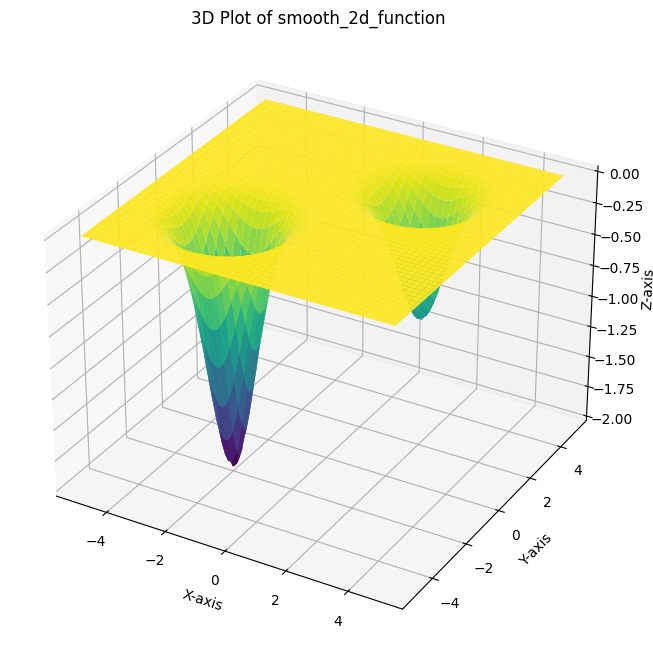

In [38]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

# Create a meshgrid for x and y values
x_vals = torch.linspace(-5, 5, 100)
y_vals = torch.linspace(-5, 5, 100)
X, Y = torch.meshgrid(x_vals, y_vals, indexing='xy')

# Calculate Z values using the smooth_2d_function
Z = smooth_2d_function(X, Y)

# Convert to numpy for plotting
X_np = X.numpy()
Y_np = Y.numpy()
Z_np = Z.numpy()

# Create the 3D plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot the surface
ax.plot_surface(X_np, Y_np, Z_np, cmap='viridis')

ax.set_xlabel('X-axis')
ax.set_ylabel('Y-axis')
ax.set_zlabel('Z-axis')
ax.set_title('3D Plot of smooth_2d_function')

plt.show()

# Extension: some actual machine learning

So far our "machine" had no inputs. Let's give it one. We'll try to **predict a man's weight from his height**.

Our training set is 100 adult men from an anthropometric survey. For each man we have his height (cm) and weight (kg). Let's start by looking at the data.

In [45]:
import matplotlib.pyplot as plt

heights = torch.tensor([166, 176, 174, 180, 168, 168, 177, 175, 169, 168, 176, 171, 165, 174, 184,
           171, 165, 173, 183, 184, 191, 172, 174, 166, 168, 174, 166, 164, 170, 172,
           167, 166, 184, 168, 168, 180, 188, 170, 180, 170, 175, 187, 172, 178, 172,
           178, 168, 165, 165, 172, 178, 168, 174, 166, 167, 187, 179, 180, 176, 173,
           181, 166, 178, 173, 168, 170, 181, 177, 176, 174, 181, 169, 167, 184, 168,
           173, 167, 183, 164, 178, 177, 186, 172, 168, 175, 164, 168, 178, 166, 180,
           178, 164, 191, 168, 178, 167, 165, 174, 166, 162], dtype=torch.float32)

weights = torch.tensor([64.0, 58.6, 68.2, 67.0, 66.9, 56.6, 85.1, 74.5, 69.7, 65.8, 61.6, 67.4, 70.8, 58.1, 74.8,
           69.4, 68.4, 78.9, 89.6, 61.8, 90.1, 89.7, 64.2, 57.0, 70.0, 80.5, 62.9, 59.0, 67.3, 88.0,
           75.3, 61.2, 99.1, 59.6, 63.8, 89.2, 74.8, 59.3, 67.9, 65.6, 78.3, 69.7, 71.3, 78.8, 66.6,
           64.9, 79.2, 66.5, 62.1, 56.9, 63.6, 81.0, 72.4, 85.3, 76.6, 74.8, 80.7, 70.7, 75.5, 71.0,
           59.1, 69.9, 97.6, 81.1, 72.0, 65.3, 66.7, 83.8, 85.3, 77.1, 93.2, 69.4, 73.8, 64.8, 67.9,
           93.6, 75.4, 77.3, 70.5, 83.9, 80.0, 103.5, 70.5, 74.3, 74.4, 57.1, 80.4, 72.3, 70.1, 69.5,
           81.2, 66.1, 74.8, 64.2, 82.6, 74.1, 63.9, 71.3, 68.0, 53.2])

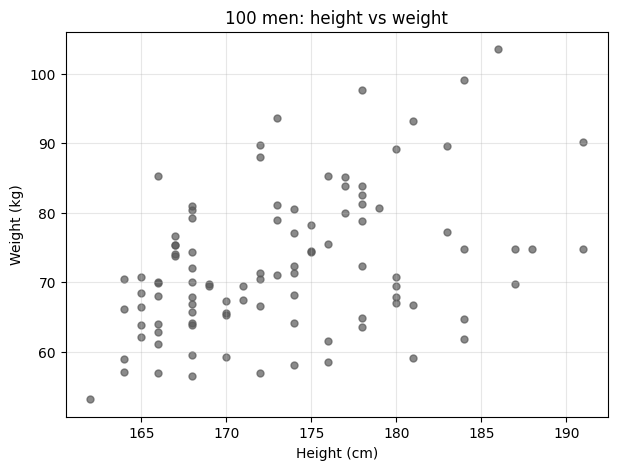

In [46]:
plt.figure(figsize=(7, 5))
plt.scatter(heights, weights, s=25, color='0.35', alpha=0.7)
plt.xlabel('Height (cm)')
plt.ylabel('Weight (kg)')
plt.title('100 men: height vs weight')
plt.grid(alpha=0.3)
plt.show()

Taller people tend to be heavier, and the relationship looks roughly linear. So let's fit a straight line: a machine with **one input, one output and two parameters**:

$$\text{weight} = c + m\,(\text{height} - 170)$$

- $m$ is the **slope**: how many extra kg per extra cm of height.
- $c$ is the **intercept**: the predicted weight of a man who is 170 cm tall. (We measure height relative to 170 cm so that $c$ means something sensible.)

The loss is the same idea as before: the mean squared difference between what the machine predicts and the true weights in the training set:

$$L(c, m) = \frac{1}{n}\sum_{i=1}^n \big(c + m(h_i - 170) - w_i\big)^2$$

For the initialisation we use an old rule of thumb: [Broca's formula](https://en.wikipedia.org/wiki/Broca_index). Paul Broca was a 19th century French surgeon and anthropologist (better known for Broca's area of the brain). He suggested that a man's "ideal" weight is

$$	ext{weight (kg)} = 	ext{height (cm)} - 100$$

So a 170 cm man should weigh 70 kg, plus 1 kg for every extra cm. In our model that is exactly $c=70$, $m=1$. It's a guess, not a fit to any data, so it makes a reasonable starting point. Let's see how good it is.

In [49]:
def predict(heights, intercept, slope):
    return intercept + slope * (heights - 170)

# Initialise with Broca's formula: 70 kg at 170 cm, +1 kg per cm
intercept = torch.tensor(70.0, requires_grad=True)
slope = torch.tensor(1.0, requires_grad=True)

optim = torch.optim.SGD([intercept, slope], lr=0.005)
loss_fn = torch.nn.MSELoss()

## The loss landscape

Before training, let's look at what we are about to minimise. Because the machine has just two parameters, we can compute the loss for every combination of intercept $c$ and slope $m$ on a grid and plot it as a surface, just like `smooth_2d_function` in the extra challenge. The orange dot is where Broca's formula puts us. Training has to roll that point downhill to the bottom of the bowl.

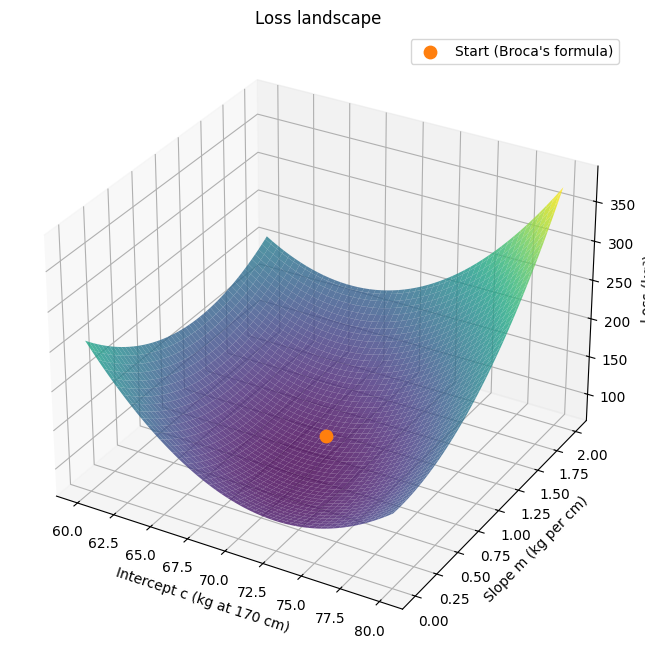

In [47]:
# Evaluate the loss on a grid of (intercept, slope) values
C3, M3 = torch.meshgrid(torch.linspace(60, 80, 100), torch.linspace(0, 2, 100), indexing='xy')
L3 = ((predict(heights[:, None, None], C3, M3) - weights[:, None, None]) ** 2).mean(dim=0)
start_loss = loss_fn(predict(heights, 70.0, 1.0), weights)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d', computed_zorder=False)
ax.plot_surface(C3, M3, L3, cmap='viridis', alpha=0.8)
ax.scatter(70, 1, start_loss, color='tab:orange', s=80, depthshade=False, zorder=10, label="Start (Broca's formula)")
ax.set_xlabel('Intercept c (kg at 170 cm)')
ax.set_ylabel('Slope m (kg per cm)')
ax.set_zlabel('Loss (kg²)')
ax.set_title('Loss landscape')
ax.legend()
plt.show()

## Training

The training loop has exactly the same structure as before. The only new thing is that we keep a record of the parameters and the loss at every step so we can visualise training afterwards.

In [50]:
niter = 1000
history = []   # (intercept, slope, loss) at every step
for step in range(niter):
    loss = loss_fn(predict(heights, intercept, slope), weights)
    history.append((intercept.item(), slope.item(), loss.item()))
    optim.zero_grad()
    loss.backward()
    optim.step()
    if not step % 100:
        print("Step %d, loss %0.3f, intercept %0.3f, slope %0.4f" % (step, loss.item(), intercept.item(), slope.item()))

print("Final: weight = %0.2f + %0.3f * (height - 170)" % (intercept.item(), slope.item()))

Step 0, loss 93.027, intercept 69.992, slope 0.7964
Step 100, loss 85.664, intercept 70.228, slope 0.6310
Step 200, loss 85.639, intercept 70.336, slope 0.6246
Step 300, loss 85.634, intercept 70.385, slope 0.6218
Step 400, loss 85.633, intercept 70.406, slope 0.6205
Step 500, loss 85.633, intercept 70.416, slope 0.6199
Step 600, loss 85.633, intercept 70.420, slope 0.6197
Step 700, loss 85.633, intercept 70.422, slope 0.6196
Step 800, loss 85.633, intercept 70.423, slope 0.6195
Step 900, loss 85.633, intercept 70.423, slope 0.6195
Final: weight = 70.42 + 0.620 * (height - 170)


Least squares line fitting has a closed form solution, just like the mean did. We can check that gradient descent found the same answer:

In [24]:
m_ls, c_ls = np.polyfit(heights.numpy() - 170, weights.numpy(), 1)
print("Closed form:      intercept %0.3f, slope %0.4f" % (c_ls, m_ls))
print("Gradient descent: intercept %0.3f, slope %0.4f" % (intercept.item(), slope.item()))

Closed form:      intercept 70.424, slope 0.6195
Gradient descent: intercept 70.423, slope 0.6195


## Visualising training

**1. How the line moved during training.** Grey dashed line = Broca's formula (the initialisation). Blue lines = snapshots during training (light = early, dark = late).

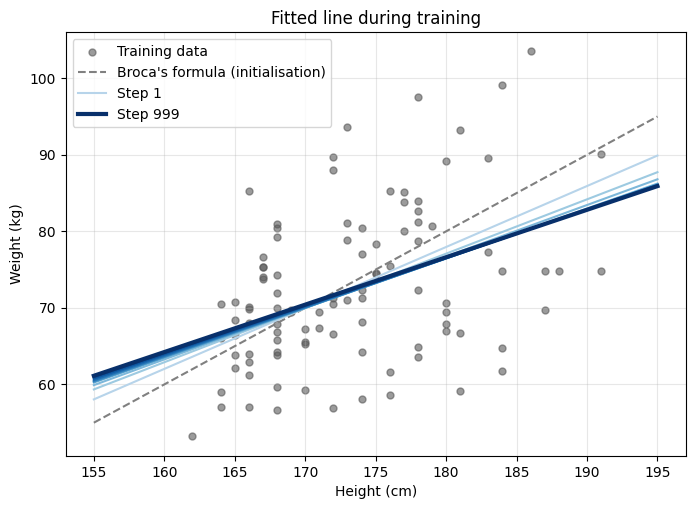

In [51]:
h_plot = torch.linspace(155, 195, 2)
snapshots = [1, 2, 3, 5, 10, 25, 50, 100, 200, niter - 1]
cmap = plt.cm.Blues

plt.figure(figsize=(8, 5.5))
plt.scatter(heights, weights, s=25, color='0.35', alpha=0.6, label='Training data')
plt.plot(h_plot, predict(h_plot, 70.0, 1.0), '--', color='0.5', lw=1.5, label="Broca's formula (initialisation)")
for k, s in enumerate(snapshots):
    c, m, _ = history[s]
    plt.plot(h_plot, predict(h_plot, c, m), color=cmap(0.3 + 0.7 * k / (len(snapshots) - 1)), lw=1.5 if s < niter - 1 else 3,
             label='Step %d' % s if s in (1, niter - 1) else None)
plt.xlabel('Height (cm)')
plt.ylabel('Weight (kg)')
plt.title('Fitted line during training')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**2. The loss curve, and the path through the loss landscape.** Because our machine has just two parameters, we can view the loss landscape from above as a contour map, zoomed in around the minimum. Each training step moves one point downhill on this map. The star marks the closed form solution.

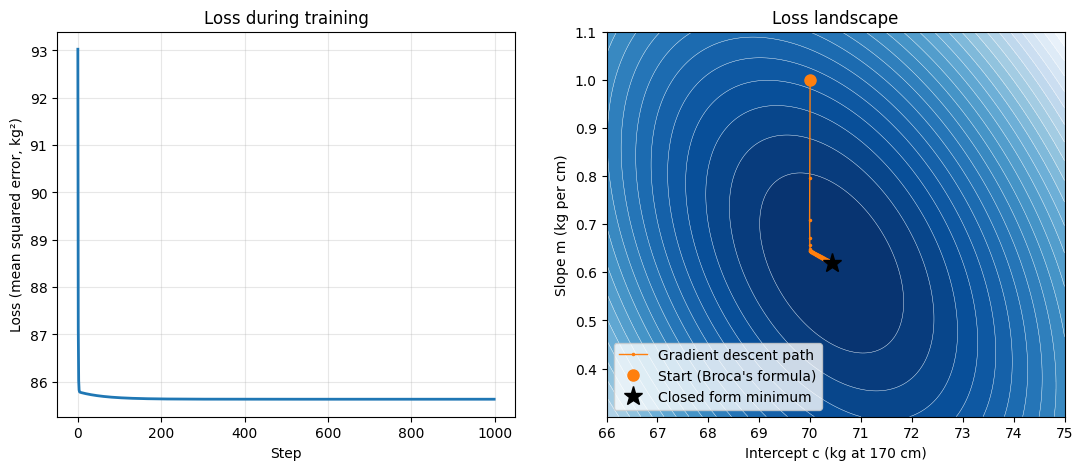

In [52]:
hist = np.array(history)

# Zoomed-in grid around the minimum
C, M = torch.meshgrid(torch.linspace(66, 75, 200), torch.linspace(0.3, 1.1, 200), indexing='xy')
L = ((predict(heights[:, None, None], C, M) - weights[:, None, None]) ** 2).mean(dim=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.plot(hist[:, 2], color='tab:blue', lw=2)
ax1.set_xlabel('Step')
ax1.set_ylabel('Loss (mean squared error, kg²)')
ax1.set_title('Loss during training')
ax1.grid(alpha=0.3)

cs = ax2.contourf(C, M, L, levels=np.geomspace(L.min().item(), L.max().item(), 25), cmap='Blues_r')
ax2.contour(C, M, L, levels=cs.levels, colors='white', linewidths=0.3)
ax2.plot(hist[:, 0], hist[:, 1], '.-', color='tab:orange', lw=1, ms=3, label='Gradient descent path')
ax2.plot(70, 1, 'o', color='tab:orange', ms=8, label="Start (Broca's formula)")
ax2.plot(c_ls, m_ls, '*', color='black', ms=14, label='Closed form minimum')
ax2.set_xlabel('Intercept c (kg at 170 cm)')
ax2.set_ylabel('Slope m (kg per cm)')
ax2.set_title('Loss landscape')
ax2.legend(loc='lower left')
plt.show()

**3. Using the trained machine.** Now we can make predictions for new inputs, and look at how wrong the model is on the training data (the *residuals*).

Predicted weight of a 165 cm man: 67.3 kg
Predicted weight of a 175 cm man: 73.5 kg
Predicted weight of a 185 cm man: 79.7 kg
Typical error (root mean squared error): 9.3 kg


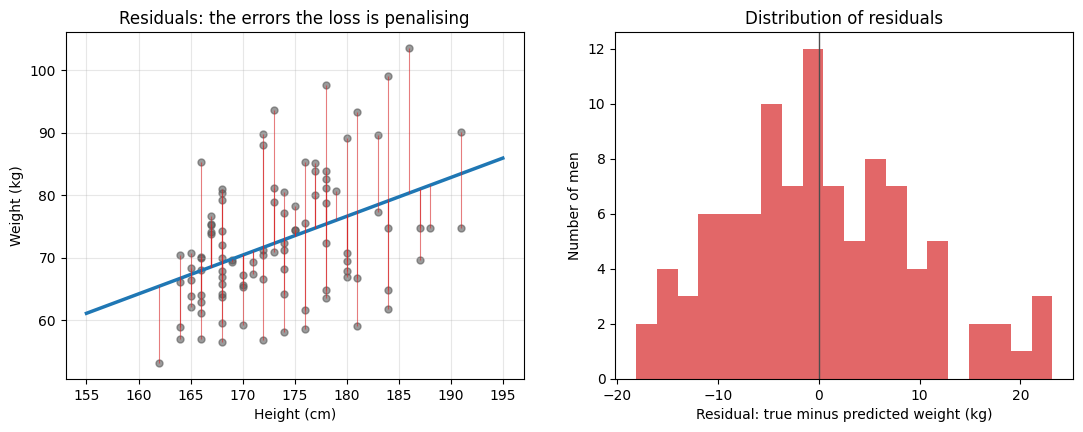

In [27]:
for h in [165, 175, 185]:
    print("Predicted weight of a %d cm man: %0.1f kg" % (h, predict(torch.tensor(h), intercept, slope).item()))

residuals = (weights - predict(heights, intercept, slope)).detach()
print("Typical error (root mean squared error): %0.1f kg" % residuals.pow(2).mean().sqrt())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
fitted = predict(heights, intercept, slope).detach()
ax1.scatter(heights, weights, s=25, color='0.35', alpha=0.6)
ax1.plot(h_plot, predict(h_plot, intercept, slope).detach(), color='tab:blue', lw=2.5)
ax1.vlines(heights, fitted, weights, color='tab:red', lw=0.8, alpha=0.6)
ax1.set_xlabel('Height (cm)')
ax1.set_ylabel('Weight (kg)')
ax1.set_title('Residuals: the errors the loss is penalising')
ax1.grid(alpha=0.3)

ax2.hist(residuals, bins=20, color='tab:red', alpha=0.7)
ax2.axvline(0, color='0.3', lw=1)
ax2.set_xlabel('Residual: true minus predicted weight (kg)')
ax2.set_ylabel('Number of men')
ax2.set_title('Distribution of residuals')
plt.show()

## Things to try

1. Increase the learning rate to `0.01` and then `0.02`. What happens, and why? (Look at the loss landscape.)
2. Swap `MSELoss` for `L1Loss`. Earlier, switching from squared to absolute differences turned the mean into the median. What does it do to the fitted line? Look at the heaviest man in the dataset.
3. Try a different initialisation. Does gradient descent still find the closed form minimum? Why is that different from the extra challenge?